# 04 — Rede neural (MLP) com PyTorch

No notebook 03 construímos a regressão logística como uma rede de **um único neurônio**. Agora acrescentamos **camadas ocultas** e, com elas, os problemas típicos de Deep Learning: escolher a arquitetura, separar um conjunto de validação, reconhecer o *overfitting* e combatê-lo com regularização e *early stopping*.

Roteiro:

1. Por que camadas ocultas e funções de ativação.
2. Conjunto de validação.
3. A arquitetura (`nn.Module`).
4. O laço de treino completo, com validação e *early stopping*.
5. Demonstração de *overfitting*.
6. Regularização: *weight decay* (L2), *dropout* e *early stopping*.
7. Seleção da configuração no conjunto de validação.
8. Avaliação final no teste.
9. Variabilidade entre sementes aleatórias.
10. Comparação com os modelos do scikit-learn.

In [1]:
import copy
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

from diabetes.config import FEATURES, RANDOM_SEED, TABLES_DIR
from diabetes.data import load_splits
from diabetes.evaluation import METRIC_ORDER, best_threshold_fbeta, bootstrap_ci, compute_metrics, plot_confusion_matrix
from diabetes.plotting import NEUTRAL, apply_style, save_fig
from diabetes.preprocessing import build_preprocessor

apply_style()
pd.set_option("display.precision", 3)
_ = torch.manual_seed(RANDOM_SEED)

## 1. Por que camadas ocultas? E por que funções de ativação?

Uma **MLP** (*multilayer perceptron*) empilha camadas lineares. Cada camada oculta transforma as variáveis em uma nova **representação**, e a última camada faz uma regressão logística sobre essa representação aprendida:

$$\mathbf{h}_1 = f(W_1\mathbf{x} + \mathbf{b}_1) \qquad \mathbf{h}_2 = f(W_2\mathbf{h}_1 + \mathbf{b}_2) \qquad z = \mathbf{w}_3\cdot\mathbf{h}_2 + b_3$$

**A função de ativação $f$ é indispensável.** Sem ela, duas camadas lineares colapsam em uma só:

$$W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = \underbrace{(W_2W_1)}_{W'}\mathbf{x} + \underbrace{(W_2\mathbf{b}_1 + \mathbf{b}_2)}_{\mathbf{b}'}$$

e a rede inteira voltaria a ser uma regressão logística, por mais camadas que tivesse. A não linearidade é o que permite à rede representar fronteiras de decisão curvas e interações entre variáveis. (O *teorema da aproximação universal* garante que uma camada oculta larga o suficiente aproxima qualquer função contínua.)

### Funções de ativação mais comuns

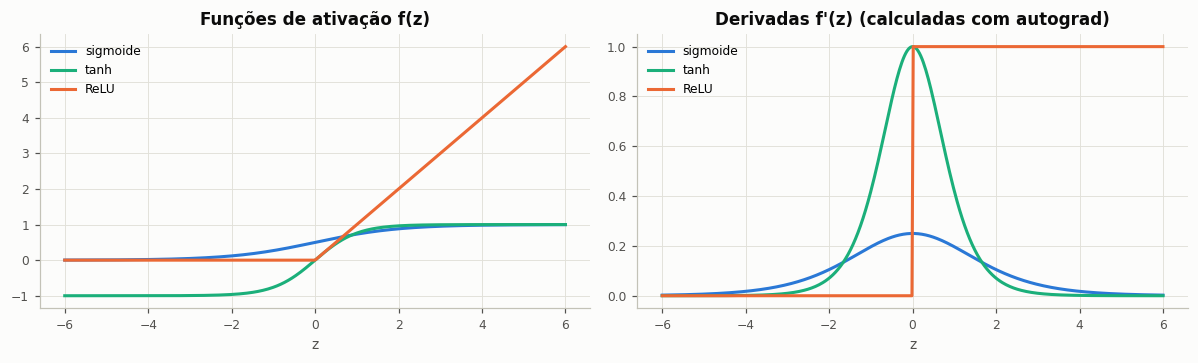

In [2]:
z = torch.linspace(-6, 6, 400, requires_grad=True)
activations = {"sigmoide": torch.sigmoid, "tanh": torch.tanh, "ReLU": torch.relu}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (name, f), color in zip(activations.items(), ["#2a78d6", "#1baf7a", "#eb6834"]):
    out = f(z)
    grad, = torch.autograd.grad(out.sum(), z)          # derivada calculada pelo autograd
    axes[0].plot(z.detach(), out.detach(), color=color, linewidth=2, label=name)
    axes[1].plot(z.detach(), grad, color=color, linewidth=2, label=name)
axes[0].set_title("Funções de ativação f(z)")
axes[1].set_title("Derivadas f'(z) (calculadas com autograd)")
for ax in axes:
    ax.set_xlabel("z")
    ax.legend()
fig.tight_layout()
save_fig(fig, "23_funcoes_ativacao")
plt.show()

| Função | Fórmula | Derivada máxima | Observação |
|---|---|---|---|
| Sigmoide | $1/(1+e^{-z})$ | **0,25** | Útil na **saída** (probabilidade). Nas camadas ocultas, satura: para $|z|$ grande a derivada ≈ 0. |
| tanh | $(e^z - e^{-z})/(e^z + e^{-z})$ | 1 | Centrada em zero, mas também satura. |
| **ReLU** | $\max(0, z)$ | 1 | Derivada 1 para $z > 0$: não satura. É o padrão moderno nas camadas ocultas. |

**Gradiente que desaparece** (*vanishing gradient*). Na backpropagation, o gradiente de uma camada inicial é um **produto** de derivadas de todas as camadas seguintes (regra da cadeia). Com sigmoide, cada fator é no máximo 0,25; com 5 camadas, $0{,}25^5 \approx 0{,}001$, e as primeiras camadas praticamente não aprendem. A ReLU, com derivada 1, evita isso. Por isso usamos **ReLU nas camadas ocultas**, e a sigmoide só na saída (embutida no `BCEWithLogitsLoss`).

## 2. Conjunto de validação

Uma rede neural tem decisões que precisam de dados "não vistos" durante o treino: **quando parar** (early stopping) e **qual arquitetura e regularização usar**. O conjunto de teste não pode ser usado para isso (seria vazamento), e a validação cruzada repetida seria cara e complicaria o early stopping. Por isso separamos **20% do treino** como **validação**, de forma estratificada:

| Conjunto | Pacientes | Uso |
|---|---|---|
| Treino da rede | 491 | Atualizar os pesos (gradiente). |
| Validação | 123 | Early stopping e escolha da configuração. |
| Teste | 154 | **Somente** a avaliação final (o mesmo dos outros modelos). |

O pré-processador (mediana, μ, σ) é ajustado **só nas 491 pacientes de treino da rede**, para que a validação simule dados novos de verdade.

*Consequência:* a rede aprende com 491 pacientes, enquanto os modelos do scikit-learn usaram as 614. Isso é uma pequena desvantagem para a rede, que deve ser lembrada na comparação.

In [3]:
X_train_full, y_train_full, X_test_df, y_test_s = load_splits()
X_tr_df, X_val_df, y_tr_s, y_val_s = train_test_split(
    X_train_full, y_train_full, test_size=0.20, stratify=y_train_full, random_state=RANDOM_SEED)

prep = build_preprocessor().fit(X_tr_df)


def to_tensors(X_df, y_s):
    X = torch.tensor(prep.transform(X_df), dtype=torch.float32)
    y = torch.tensor(y_s.values, dtype=torch.float32).unsqueeze(1)
    return X, y


X_tr, y_tr = to_tensors(X_tr_df, y_tr_s)
X_val, y_val = to_tensors(X_val_df, y_val_s)
X_test, y_test = to_tensors(X_test_df, y_test_s)
for name, (X, y) in {"treino da rede": (X_tr, y_tr), "validação": (X_val, y_val), "teste": (X_test, y_test)}.items():
    print(f"{name:15s} X={tuple(X.shape)}  y={tuple(y.shape)}  positivas={int(y.sum())} ({y.mean():.1%})")

treino da rede  X=(491, 8)  y=(491, 1)  positivas=171 (34.8%)
validação       X=(123, 8)  y=(123, 1)  positivas=43 (35.0%)
teste           X=(154, 8)  y=(154, 1)  positivas=54 (35.1%)


## 3. A arquitetura

A classe abaixo monta uma MLP com qualquer número de camadas ocultas:

```
entrada (8) → [Linear → ReLU → Dropout] × camadas ocultas → Linear → 1 logit
```

O *dropout* é explicado na §6. A saída é um **logit**, pelos motivos de estabilidade numérica vistos no notebook 03.

In [4]:
class MLP(nn.Module):
    # Perceptron multicamadas para classificação binária (saída = logit).

    def __init__(self, n_features: int, hidden: tuple = (16, 8), dropout: float = 0.0):
        super().__init__()
        layers, n_in = [], n_features
        for n_out in hidden:
            layers += [nn.Linear(n_in, n_out), nn.ReLU(), nn.Dropout(dropout)]
            n_in = n_out
        layers.append(nn.Linear(n_in, 1))
        self.net = nn.Sequential(*layers)       # executa as camadas em sequência

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


demo = MLP(8, hidden=(16, 8), dropout=0.3)
print(demo)
print("\nParâmetros por camada:")
for name, p in demo.named_parameters():
    print(f"  {name:14s} shape={str(tuple(p.shape)):9s} -> {p.numel():4d}")
print(f"Total: {count_parameters(demo)} parâmetros  (a regressão logística tem 9)")

MLP(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)

Parâmetros por camada:
  net.0.weight   shape=(16, 8)   ->  128
  net.0.bias     shape=(16,)     ->   16
  net.3.weight   shape=(8, 16)   ->  128
  net.3.bias     shape=(8,)      ->    8
  net.6.weight   shape=(1, 8)    ->    8
  net.6.bias     shape=(1,)      ->    1
Total: 289 parâmetros  (a regressão logística tem 9)


Contagem: a camada $8 \to 16$ tem $8 \times 16$ pesos $+ 16$ vieses $= 144$; a $16 \to 8$ tem $16 \times 8 + 8 = 136$; a $8 \to 1$ tem $8 + 1 = 9$. Total: **289 parâmetros**.

## 4. O laço de treino completo

Em relação ao notebook 03, o laço ganha três elementos:

- **`model.train()` / `model.eval()`**: alternam o comportamento de camadas como o dropout, que só deve atuar no treino.
- **Avaliação na validação a cada época**, dentro de `torch.no_grad()` (não precisa montar o grafo de gradientes, o que economiza memória e tempo).
- ***Early stopping***: guardamos os pesos da época com **menor perda de validação**. Se ela não melhorar por `patience` épocas seguidas, paramos e restauramos esses pesos.

O otimizador é o **Adam** (notebook 03, §8), com lotes de 32.

In [5]:
N_FEATURES = X_tr.shape[1]
loss_fn = nn.BCEWithLogitsLoss()


def train_mlp(hidden=(16, 8), dropout=0.0, weight_decay=0.0, lr=1e-3, batch_size=32,
              max_epochs=500, patience=None, seed=RANDOM_SEED):
    # Treina uma MLP; com `patience`, aplica early stopping e restaura os melhores pesos.
    torch.manual_seed(seed)
    model = MLP(N_FEATURES, hidden, dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = {"train_loss": [], "val_loss": [], "val_auc": []}
    best = {"val_loss": float("inf"), "epoch": 0, "state": None}

    for epoch in range(1, max_epochs + 1):
        model.train()                                  # dropout ligado
        for xb, yb in loader:
            optimizer.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimizer.step()

        model.eval()                                   # dropout desligado
        with torch.no_grad():
            history["train_loss"].append(loss_fn(model(X_tr), y_tr).item())
            val_logits = model(X_val)
            history["val_loss"].append(loss_fn(val_logits, y_val).item())
            history["val_auc"].append(roc_auc_score(y_val_s, torch.sigmoid(val_logits).numpy().ravel()))

        if history["val_loss"][-1] < best["val_loss"] - 1e-4:
            best = {"val_loss": history["val_loss"][-1], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        elif patience is not None and epoch - best["epoch"] >= patience:
            break                                      # early stopping

    if patience is not None:
        model.load_state_dict(best["state"])           # volta para a melhor época
    return model, history, best["epoch"]


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).numpy().ravel()


def plot_history(ax, history, best_epoch, title, mark_best=True):
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], color="#2a78d6", linewidth=2, label="treino")
    ax.plot(epochs, history["val_loss"], color="#eb6834", linewidth=2, label="validação")
    if mark_best:
        ax.axvline(best_epoch, color=NEUTRAL, linestyle="--", linewidth=1.2, label=f"menor perda de validação (época {best_epoch})")
    ax.set_xlabel("Época")
    ax.set_ylabel("Perda BCE")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7)

## 5. Demonstração de *overfitting*

**Overfitting** é quando o modelo **memoriza** particularidades do treino (inclusive o ruído) em vez de aprender padrões que generalizam. O sinal clássico: a perda de treino continua caindo enquanto a perda de validação **para de cair e volta a subir**.

Para provocá-lo, usamos uma rede **grande** para o tamanho do problema (8 → 64 → 64 → 1, com cerca de 4,8 mil parâmetros para 491 pacientes), **sem nenhuma regularização**, treinada por 400 épocas com taxa de aprendizado 0,005.

Parâmetros: 4801
Menor perda de validação: 0.4197 na época 2
Ao final (época 400): treino = 0.0003 | validação = 2.8097
ROC-AUC de validação: na melhor época = 0.873 | ao final = 0.795


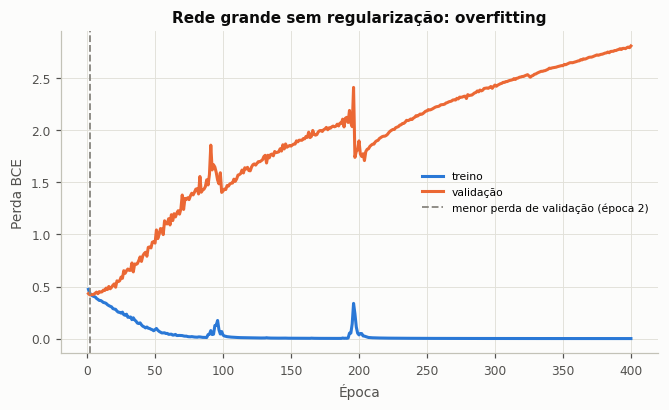

In [6]:
big_model, big_hist, big_best = train_mlp(hidden=(64, 64), dropout=0.0, weight_decay=0.0, lr=5e-3, max_epochs=400)
print(f"Parâmetros: {count_parameters(big_model)}")
print(f"Menor perda de validação: {min(big_hist['val_loss']):.4f} na época {big_best}")
print(f"Ao final (época 400): treino = {big_hist['train_loss'][-1]:.4f} | validação = {big_hist['val_loss'][-1]:.4f}")
print(f"ROC-AUC de validação: na melhor época = {big_hist['val_auc'][big_best - 1]:.3f} | ao final = {big_hist['val_auc'][-1]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
plot_history(ax, big_hist, big_best, "Rede grande sem regularização: overfitting")
save_fig(fig, "24_overfitting_sem_regularizacao")
plt.show()

**Observações**

- Este é um caso de *overfitting* clássico, e extremo:
  - A **perda de treino cai para ≈ 0,0003**: a rede praticamente memorizou as 491 pacientes.
  - A **perda de validação atinge o mínimo (0,420) já na época 2** e depois **sobe sem parar**, até 2,81 na época 400.
- Por que a perda de validação explode? A rede passa a dar probabilidades **extremamente confiantes** (próximas de 0 ou 1). Quando erra uma paciente de validação com essa confiança, a BCE cobra $-\log(\approx 0)$, um valor enorme (notebook 03, §3.2).
- A **ROC-AUC de validação** também piora, de 0,873 na época 2 para 0,795 ao final, mas bem menos que a perda. A ordenação das pacientes se degrada mais devagar que a calibração das probabilidades.
- Os picos nas curvas (por volta das épocas 90 e 200) são instabilidades típicas do Adam com taxa de aprendizado alta quando a perda de treino já está próxima de zero.
- **Lição:** com 4,8 mil parâmetros e 491 pacientes, a rede tem capacidade de sobra para decorar o treino. Sem um mecanismo de controle, o modelo final seria muito pior que o modelo de poucas épocas atrás.

## 6. Regularização

Três técnicas complementares, todas disponíveis no PyTorch:

**1. *Weight decay* (penalidade L2).** É a mesma ideia do parâmetro `C` da regressão logística: somamos à perda um termo que penaliza pesos grandes,

$$L_{\text{total}} = L_{\text{BCE}} + \frac{\lambda}{2}\lVert\mathbf{w}\rVert^2 \quad\Rightarrow\quad \nabla L_{\text{total}} = \nabla L_{\text{BCE}} + \lambda\,\mathbf{w}$$

A cada passo, os pesos "encolhem" um pouco em direção a zero, o que favorece funções mais suaves. No PyTorch: `torch.optim.Adam(..., weight_decay=λ)`. (A variante `AdamW` aplica o decaimento de forma "desacoplada" do gradiente adaptativo, o que costuma funcionar melhor em redes grandes.)

**2. *Dropout*.** Durante o treino, cada neurônio oculto é **desligado** (zerado) com probabilidade $p$, sorteado de novo a cada lote. Os que sobram são multiplicados por $1/(1-p)$ para manter a escala. Como nenhum neurônio pode contar com a presença de outro específico, a rede é forçada a aprender representações **redundantes e robustas**. Na avaliação (`model.eval()`) o dropout é desligado; isso equivale, aproximadamente, a tirar a média de um conjunto enorme de sub-redes.

**3. *Early stopping*.** Interrompe o treino quando a perda de validação para de melhorar e restaura os pesos da melhor época. Como o número de épocas também controla a complexidade do modelo, parar cedo é, por si só, uma forma de regularização.

Abaixo, **a mesma rede grande** com as três técnicas: dropout 0,3, weight decay $10^{-3}$, e early stopping com paciência de 40 épocas.

Parou na época 52; pesos restaurados da época 12
Perda de validação (melhor época): 0.4124  |  sem regularização: melhor 0.4197, final 2.8097
ROC-AUC de validação (melhor época): 0.879


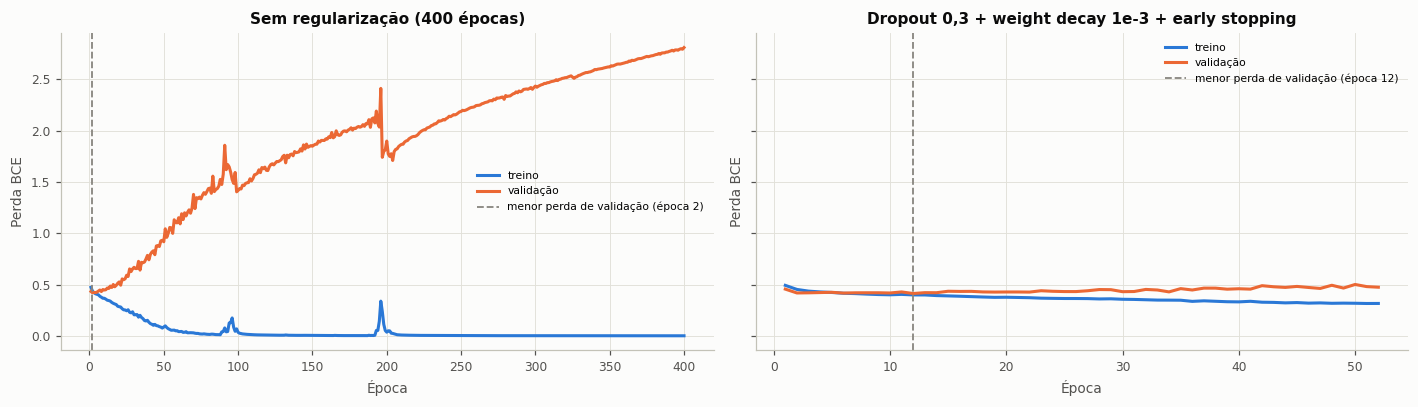

In [7]:
reg_model, reg_hist, reg_best = train_mlp(hidden=(64, 64), dropout=0.3, weight_decay=1e-3, lr=5e-3,
                                          max_epochs=400, patience=40)
print(f"Parou na época {len(reg_hist['val_loss'])}; pesos restaurados da época {reg_best}")
print(f"Perda de validação (melhor época): {min(reg_hist['val_loss']):.4f}  |  sem regularização: "
      f"melhor {min(big_hist['val_loss']):.4f}, final {big_hist['val_loss'][-1]:.4f}")
print(f"ROC-AUC de validação (melhor época): {reg_hist['val_auc'][reg_best - 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
plot_history(axes[0], big_hist, big_best, "Sem regularização (400 épocas)")
plot_history(axes[1], reg_hist, reg_best, "Dropout 0,3 + weight decay 1e-3 + early stopping")
fig.tight_layout()
save_fig(fig, "25_efeito_regularizacao")
plt.show()

**Observações**

- Com as três técnicas juntas, a mesma arquitetura se comporta de forma completamente diferente:
  - As curvas de treino e validação **ficam próximas**.
  - O *early stopping* parou o treino na época 52 e **restaurou os pesos da época 12**.
  - A perda de validação na melhor época (**0,412**) ficou ligeiramente melhor que a melhor época sem regularização (0,420), e muito melhor que o modelo não regularizado ao final (2,81).
- O **dropout** desacelera a memorização: a perda de treino cai devagar, ficando em ≈ 0,3 em vez de ≈ 0. Assim a melhor época chega mais tarde (12 em vez de 2), com um mínimo de validação mais estável.
- O ***early stopping* é o mecanismo decisivo**: ele garante que, aconteça o que acontecer depois, o modelo entregue é o da melhor época de validação.
- *(O gráfico da direita compartilha o eixo vertical com o da esquerda para facilitar a comparação; por isso suas curvas parecem achatadas.)*

## 7. Seleção da configuração no conjunto de validação

Como no scikit-learn, os hiperparâmetros da rede são escolhidos **sem tocar no teste**. Testamos 8 combinações:

- Arquitetura: **(16, 8)** (pequena, 289 parâmetros) ou **(64, 32)** (maior, ≈ 2,7 mil parâmetros).
- Dropout: **0** ou **0,3**.
- Weight decay: **0** ou **$10^{-3}$**.

Todas com Adam (taxa 0,001), lotes de 32 e early stopping (paciência 40, até 500 épocas).

Com só 123 pacientes de validação, o resultado de **uma** inicialização aleatória é ruidoso. Por isso cada configuração é treinada com **3 sementes**, e comparamos a **ROC-AUC média de validação** (o mesmo critério usado no scikit-learn).

In [8]:
configs = [{"hidden": h, "dropout": d, "weight_decay": wd}
           for h in [(16, 8), (64, 32)] for d in [0.0, 0.3] for wd in [0.0, 1e-3]]
SELECTION_SEEDS = [0, 1, 2]

rows = []
for cfg in configs:
    aucs, losses, epochs = [], [], []
    for seed in SELECTION_SEEDS:
        model, hist, best_epoch = train_mlp(**cfg, lr=1e-3, max_epochs=500, patience=40, seed=seed)
        aucs.append(hist["val_auc"][best_epoch - 1])
        losses.append(hist["val_loss"][best_epoch - 1])
        epochs.append(best_epoch)
    rows.append({"arquitetura": str(cfg["hidden"]), "dropout": cfg["dropout"], "weight_decay": cfg["weight_decay"],
                 "parâmetros": count_parameters(MLP(N_FEATURES, cfg["hidden"])),
                 "val_auc_média": np.mean(aucs), "val_auc_desvio": np.std(aucs),
                 "val_perda_média": np.mean(losses), "melhor_época_média": np.mean(epochs)})

selection = pd.DataFrame(rows).sort_values("val_auc_média", ascending=False).reset_index(drop=True)
selection.to_csv(TABLES_DIR / "selecao_configuracao_mlp.csv", index=False)
selection

,arquitetura,dropout,weight_decay,parâmetros,val_auc_média,val_auc_desvio,val_perda_média,melhor_época_média
0,"(64, 32)",0.3,0.001,2689,0.887,0.002,0.407,13.667
1,"(64, 32)",0.3,0.000,2689,0.887,0.002,0.407,13.667
2,"(64, 32)",0.0,0.000,2689,0.884,0.003,0.408,12.333
3,"(64, 32)",0.0,0.001,2689,0.883,0.003,0.408,12.333
4,"(16, 8)",0.3,0.001,289,0.877,0.001,0.415,104.333
5,"(16, 8)",0.3,0.000,289,0.877,0.002,0.415,104.333
6,"(16, 8)",0.0,0.001,289,0.876,0.004,0.418,29.333
7,"(16, 8)",0.0,0.000,289,0.876,0.006,0.418,29.333


In [9]:
best_row = selection.iloc[0]
BEST_CFG = {"hidden": tuple(int(x) for x in best_row["arquitetura"].strip("()").split(",")),
            "dropout": float(best_row["dropout"]), "weight_decay": float(best_row["weight_decay"])}
print("Configuração escolhida:", BEST_CFG)

Configuração escolhida: {'hidden': (64, 32), 'dropout': 0.3, 'weight_decay': 0.001}


**Observações**

- **Todas as 8 configurações ficam muito próximas**: ROC-AUC média de validação entre **0,876 e 0,887**. A arquitetura maior (64, 32) ficou ≈ 0,01 à frente da menor (16, 8), e a escolhida foi **(64, 32) com dropout 0,3 e weight decay $10^{-3}$**.
- **O weight decay de $10^{-3}$ não teve efeito mensurável.** As linhas com e sem ele são idênticas até a 3ª casa decimal. Há dois motivos:
  1. O *early stopping* interrompe o treino em ≈ 12–14 épocas (arquitetura maior), cedo demais para a penalidade "encolher" os pesos de forma relevante.
  2. No Adam, o termo $\lambda\mathbf{w}$ entra no gradiente e é depois **dividido** pela escala adaptativa $\sqrt{\hat v_t}$, o que enfraquece o efeito da penalidade. É exatamente o problema que o `AdamW` (decaimento desacoplado) resolve.

  Isso é um resultado legítimo da experiência e fica registrado, sem ajustar a grade para "forçar" um efeito.
- O dropout ajudou levemente (≈ +0,003 de AUC) e, na rede pequena, fez o treino durar muito mais (melhor época ≈ 104 contra ≈ 29), porque a memorização fica mais lenta.
- **Atenção à otimização da validação.** A ROC-AUC de validação (≈ 0,88) é uma estimativa **otimista**: o mesmo conjunto de 123 pacientes foi usado para o *early stopping* e para escolher a configuração. Só o teste dá uma estimativa imparcial.

## 8. Avaliação final no teste

Treinamos a configuração escolhida com a semente do projeto (42) e avaliamos no teste com as **mesmas funções** usadas para os modelos do scikit-learn: limiar 0,5 e limiar escolhido por F2. Aqui o limiar F2 é escolhido nas probabilidades da **validação**, e não em probabilidades out-of-fold.

Treino parou na época 52; pesos da época 12 (validação: perda 0.4114, ROC-AUC 0.881)


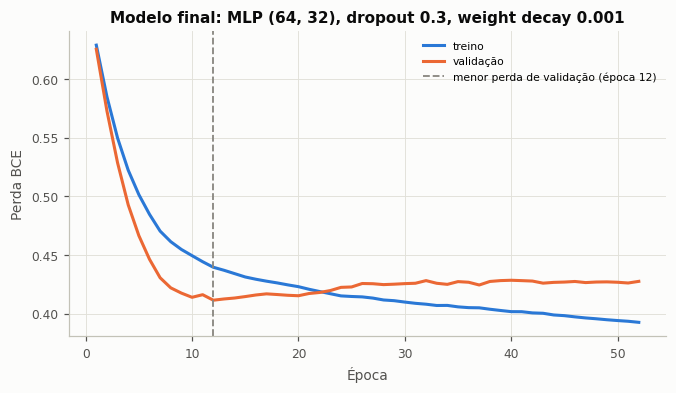

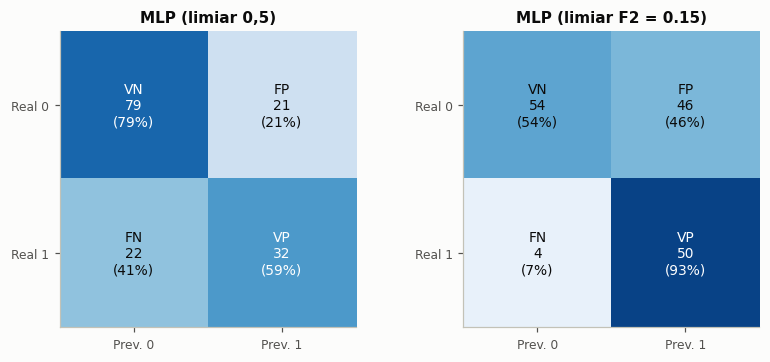

IC 95% por bootstrap (limiar 0,5): {'recall': '[0.457, 0.730]', 'f1': '[0.485, 0.704]', 'roc_auc': '[0.734, 0.872]'}


,limiar,acurácia,precisão,recall,especificidade,f1,roc_auc,VN,FP,FN,VP
"limiar 0,5",0.500,0.721,0.604,0.593,0.79,0.598,0.809,79,21,22,32
limiar F2,0.145,0.675,0.521,0.926,0.54,0.667,0.809,54,46,4,50


In [10]:
final_model, final_hist, final_best = train_mlp(**BEST_CFG, lr=1e-3, max_epochs=500, patience=40, seed=RANDOM_SEED)
print(f"Treino parou na época {len(final_hist['val_loss'])}; pesos da época {final_best} "
      f"(validação: perda {final_hist['val_loss'][final_best - 1]:.4f}, ROC-AUC {final_hist['val_auc'][final_best - 1]:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.6))
plot_history(ax, final_hist, final_best, f"Modelo final: MLP {BEST_CFG['hidden']}, dropout {BEST_CFG['dropout']}, "
                                         f"weight decay {BEST_CFG['weight_decay']}")
save_fig(fig, "26_mlp_final_curvas")
plt.show()

val_proba = predict_proba(final_model, X_val)
mlp_threshold = best_threshold_fbeta(y_val_s, val_proba, beta=2)
test_proba = predict_proba(final_model, X_test)

mlp_results = {
    "limiar 0,5": compute_metrics(y_test_s, (test_proba >= 0.5).astype(int), test_proba),
    "limiar F2": compute_metrics(y_test_s, (test_proba >= mlp_threshold).astype(int), test_proba),
}
mlp_table = pd.DataFrame(mlp_results).T
mlp_table.insert(0, "limiar", [0.5, mlp_threshold])
mlp_table[["VN", "FP", "FN", "VP"]] = mlp_table[["VN", "FP", "FN", "VP"]].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
plot_confusion_matrix(axes[0], y_test_s, (test_proba >= 0.5).astype(int), "MLP (limiar 0,5)")
plot_confusion_matrix(axes[1], y_test_s, (test_proba >= mlp_threshold).astype(int), f"MLP (limiar F2 = {mlp_threshold:.2f})")
fig.tight_layout()
save_fig(fig, "27_mlp_matrizes_confusao_teste")
plt.show()

ci = bootstrap_ci(y_test_s, (test_proba >= 0.5).astype(int), test_proba, n_boot=2000, seed=RANDOM_SEED)
print("IC 95% por bootstrap (limiar 0,5):", {m: f"[{ci.loc[m, 'ic_inferior']:.3f}, {ci.loc[m, 'ic_superior']:.3f}]"
                                            for m in ["recall", "f1", "roc_auc"]})
mlp_table

## 9. Variabilidade entre sementes

Uma rede neural parte de pesos **aleatórios** e vê os lotes em ordem **aleatória**. Diferentemente da regressão logística, sua função de perda **não é convexa**, então inicializações diferentes podem levar a soluções diferentes. Para saber quanto o resultado da §8 depende da sorte, repetimos o treino com 10 sementes. *(É uma análise de robustez; nenhuma escolha é feita com base nela.)*

In [11]:
seed_rows = []
for seed in range(10):
    model, hist, best_epoch = train_mlp(**BEST_CFG, lr=1e-3, max_epochs=500, patience=40, seed=seed)
    proba = predict_proba(model, X_test)
    m = compute_metrics(y_test_s, (proba >= 0.5).astype(int), proba)
    seed_rows.append({"semente": seed, "melhor_época": best_epoch, **{k: m[k] for k in METRIC_ORDER}})
seeds = pd.DataFrame(seed_rows).set_index("semente")
seeds.to_csv(TABLES_DIR / "mlp_variabilidade_sementes.csv")
display(seeds)
seeds[METRIC_ORDER].agg(["mean", "std", "min", "max"]).rename(index={"mean": "média", "std": "desvio", "min": "mín", "max": "máx"})

,melhor_época,acurácia,precisão,recall,especificidade,f1,roc_auc
semente,,,,,,,
0,15,0.727,0.615,0.593,0.80,0.604,0.813
1,16,0.708,0.592,0.537,0.80,0.563,0.812
2,10,0.721,0.612,0.556,0.81,0.583,0.803
3,11,0.714,0.609,0.519,0.82,0.560,0.812
4,9,0.708,0.600,0.500,0.82,0.545,0.811
5,18,0.721,0.608,0.574,0.80,0.590,0.800
6,13,0.727,0.615,0.593,0.80,0.604,0.813
7,13,0.714,0.600,0.556,0.80,0.577,0.817
8,16,0.721,0.617,0.537,0.82,0.574,0.812


,acurácia,precisão,recall,especificidade,f1,roc_auc
média,0.718,0.606,0.554,0.806,0.579,0.811
desvio,0.007,0.009,0.031,0.011,0.019,0.006
mín,0.708,0.592,0.500,0.790,0.545,0.800
máx,0.727,0.617,0.593,0.820,0.604,0.822


**Observações**

- Entre 10 sementes, a **ROC-AUC no teste é muito estável**: 0,811 ± 0,006, entre 0,800 e 0,822. O recall varia mais, 0,554 ± 0,031 (entre 0,500 e 0,593), porque depende de quais pacientes ficam logo acima ou logo abaixo do limiar 0,5.
- **O modelo da §8 (semente 42) teve recall 0,593 no teste, igual ao maior valor observado entre as 10 sementes.** Seu bom recall com limiar 0,5 é, em parte, **sorte da inicialização**. O valor típico esperado para esta configuração é ≈ 0,55.
- Esta é uma diferença importante em relação aos modelos do scikit-learn: a regressão logística, o KNN e (com `random_state` fixo) o Random Forest dão sempre o mesmo resultado, enquanto a rede neural tem uma **variabilidade intrínseca** que precisa ser relatada.

## 10. Comparação com os modelos do scikit-learn

Todos os modelos foram avaliados nas **mesmas 154 pacientes de teste**, com as mesmas métricas.

In [12]:
mlp_export = mlp_table.rename_axis("configuração").reset_index()
mlp_export.insert(0, "modelo", f"MLP {BEST_CFG['hidden']}")
mlp_export.insert(0, "ferramenta", "Python (PyTorch)")
mlp_export = mlp_export[["ferramenta", "modelo", "configuração", "limiar", *METRIC_ORDER, "VN", "FP", "FN", "VP"]]
mlp_export.to_csv(TABLES_DIR / "metricas_teste_pytorch.csv", index=False)

sk = pd.read_csv(TABLES_DIR / "metricas_teste_python.csv")
all_models = pd.concat([sk, mlp_export], ignore_index=True)
all_models.to_csv(TABLES_DIR / "metricas_teste_todos_python.csv", index=False)

view = all_models.set_index(["configuração", "modelo"])[["limiar", *METRIC_ORDER, "FN", "FP"]].sort_index(level=0, sort_remaining=False)
view.round(3)

limiar  acurácia  precisão  recall  \
configuração modelo                                                    
limiar 0,5   Regressão Logística   0.500     0.688     0.565   0.481   
             KNN                   0.500     0.740     0.667   0.519   
             Random Forest         0.500     0.727     0.650   0.481   
             MLP (64, 32)          0.500     0.721     0.604   0.593   
limiar F2    Regressão Logística   0.138     0.662     0.510   0.981   
             KNN                   0.229     0.649     0.500   0.870   
             Random Forest         0.205     0.675     0.522   0.889   
             MLP (64, 32)          0.145     0.675     0.521   0.926   

                                  especificidade     f1  roc_auc  FN  FP  
configuração modelo                                                       
limiar 0,5   Regressão Logística            0.80  0.520    0.810  28  20  
             KNN                            0.86  0.583    0.806  26  14  
             Random Forest                  0.86  0.553    0.807  28  14  
             MLP (64, 32)                   0.79  0.598    0.809  22  21  
limiar F2    Regressão Logística            0.49  0.671    0.810   1  51  
             KNN                            0.53  0.635    0.806   7  47  
             Random Forest                  0.56  0.658    0.807   6  44  
             MLP (64, 32)                   0.54  0.667    0.809   4  46

## Conclusões

1. **A rede neural não supera os modelos clássicos.** Sua ROC-AUC no teste (0,809; 0,811 ± 0,006 entre sementes) é praticamente idêntica à da Regressão Logística (0,810), do KNN (0,806) e do Random Forest (0,807). Isso confirma a expectativa da Fase 1: com 8 variáveis tabulares e ≈ 500 pacientes de treino, não há padrões complexos que só uma rede consiga capturar, e o limite parece estar na informação contida nas variáveis.
2. **Com o limiar 0,5**, a MLP teve o maior recall (0,593, ou 32 de 54) e o maior F1 (0,598). Mas o IC 95% do recall ([0,46; 0,73]) se sobrepõe aos dos outros modelos, e a análise de sementes (§9) mostra que esse valor está no extremo favorável da variação. **Não é uma vantagem real.**
3. **Com o limiar escolhido por F2** (0,145, definido na validação), a MLP detecta **50 das 54 diabéticas** (recall 0,926), com 46 falsos positivos. Fica no mesmo patamar dos outros modelos com limiar ajustado (recall 0,87–0,98).
4. **Custo-benefício:** a rede tem ≈ 2,7 mil parâmetros (contra 9 da regressão logística), precisa de um conjunto de validação (treina com 491 pacientes em vez de 614), depende de sementes aleatórias, exige mais decisões de configuração e **não é interpretável**. Para este problema, a **Regressão Logística continua sendo a escolha mais sensata**. O valor deste notebook está no aprendizado: o mesmo instrumental (tensores, autograd, `nn.Module`, `DataLoader`, Adam, dropout, early stopping) é o que se usa em problemas em que redes neurais fazem diferença, como imagens, texto e grandes volumes de dados.
5. Os resultados da MLP foram gravados em `results/tables/metricas_teste_pytorch.csv`, e a tabela conjunta em `metricas_teste_todos_python.csv`.